In [1]:
# Cell 1
import random
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import torchvision.models as models
import torchvision.transforms as transforms

def seed_everything(seed=42):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)
  torch.backends.cudnn.deterministic = True

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [2]:
# Cell 2
print("正在下載並讀入 fer2013 資料集...")

fer2013_raw_data = load_dataset(
    "Aaryan333/fer2013_train_publicTest_privateTest"
)

fer2013_train_split = (
    fer2013_raw_data["train"]
    if "train" in fer2013_raw_data
    else fer2013_raw_data["Training"]
)
fer2013_val_split = (
    fer2013_raw_data["publicTest"]
    if "publicTest" in fer2013_raw_data
    else fer2013_raw_data["PublicTest"]
)
fer2013_test_split = (
    fer2013_raw_data["privateTest"]
    if "privateTest" in fer2013_raw_data
    else fer2013_raw_data["PrivateTest"]
)

print(f"fer2013 訓練集數量: {len(fer2013_train_split)}")
print(f"fer2013 驗證集數量 (PublicTest): {len(fer2013_val_split)}")
print(f"fer2013 測試集數量 (PrivateTest): {len(fer2013_test_split)}")

正在下載並讀入 fer2013 資料集...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/750 [00:00<?, ?B/s]

data/train-00000-of-00001-5eab84e1c6a2fc(…): reconstructing file:   0%|          |  0.00B /  106MB            

data/train-00000-of-00001-5eab84e1c6a2fc(…): downloading bytes:           |  0.00B            

data/privateTest-00000-of-00001-4b8a0715(…): reconstructing file:   0%|          |  0.00B / 13.4MB            

... (3 outputs left out)

Generating train split:   0%|          | 0/28709 [00:00<?, ? examples/s]

Generating privateTest split:   0%|          | 0/3589 [00:00<?, ? examples/s]

Generating publicTest split:   0%|          | 0/3589 [00:00<?, ? examples/s]

fer2013 訓練集數量: 28709
fer2013 驗證集數量 (PublicTest): 3589
fer2013 測試集數量 (PrivateTest): 3589


In [3]:
# Cell 3
train_fer2013_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomResizedCrop(224, scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_test_fer2013_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


class FER2013DatasetWrapper(Dataset):

  def __init__(self, hf_data, transform=None):
    self.data = hf_data
    self.transform = transform

  def __len__(self):
    return len(self.data)

  def __getitem__(self, idx):
    item = self.data[idx]
    image = item["image"]
    # 確保轉為 PIL RGB 3 通道
    if not isinstance(image, Image.Image):
      image = Image.fromarray(image)
    image = image.convert("RGB")
    label = int(item["label"])

    if self.transform:
      image = self.transform(image)

    return image, label

BATCH_SIZE = 64
train_loader = DataLoader(
    FER2013DatasetWrapper(
        fer2013_train_split, transform=train_fer2013_transforms
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)

val_loader = DataLoader(
    FER2013DatasetWrapper(
        fer2013_val_split, transform=val_test_fer2013_transforms
    ),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

test_loader = DataLoader(
    FER2013DatasetWrapper(
        fer2013_test_split, transform=val_test_fer2013_transforms
    ),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

In [4]:
# Cell 4
model = models.resnet18(weights="IMAGENET1K_V1")

num_classes = 7

model.fc = nn.Sequential(
    nn.Dropout(p=0.4), nn.Linear(model.fc.in_features, num_classes)
)

model = model.to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = optim.AdamW(
    model.parameters(), lr=2e-4, weight_decay=1e-3
)

EPOCHS = 12
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=1e-6
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


 30%|██▉       | 13.2M/44.7M [00:00<00:00, 139MB/s]

100%|██████████| 44.7M/44.7M [00:00<00:00, 191MB/s]


In [5]:
# Cell 5
train_losses, train_accs = [], []
val_losses, val_accs = [], []

print("開始訓練模型...")
for epoch in range(1, EPOCHS + 1):
  # Training
  model.train()
  train_running_loss = 0.0
  train_correct = 0
  train_total = 0

  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    train_running_loss += loss.item() * images.size(0)
    _, predicted = outputs.max(1)
    train_total += labels.size(0)
    train_correct += predicted.eq(labels).sum().item()

  train_loss = train_running_loss / train_total
  train_acc = train_correct / train_total

  # Validation
  model.eval()
  val_running_loss = 0.0
  val_correct = 0
  val_total = 0

  with torch.no_grad():
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)
      loss = criterion(outputs, labels)

      val_running_loss += loss.item() * images.size(0)
      _, predicted = outputs.max(1)
      val_total += labels.size(0)
      val_correct += predicted.eq(labels).sum().item()

  val_loss = val_running_loss / val_total
  val_acc = val_correct / val_total

  scheduler.step()

  train_losses.append(train_loss)
  train_accs.append(train_acc)
  val_losses.append(val_loss)
  val_accs.append(val_acc)

  print(
      f"Epoch {epoch}/{EPOCHS} - train_loss: {train_loss:.2f} - train_acc:"
      f" {train_acc:.2f} - val_loss: {val_loss:.2f} - val_acc: {val_acc:.2f}"
  )

開始訓練模型...
Epoch 1/12 - train_loss: 1.32 - train_acc: 0.54 - val_loss: 1.16 - val_acc: 0.61
Epoch 2/12 - train_loss: 1.12 - train_acc: 0.62 - val_loss: 1.10 - val_acc: 0.63
Epoch 3/12 - train_loss: 1.05 - train_acc: 0.66 - val_loss: 1.08 - val_acc: 0.66
Epoch 4/12 - train_loss: 0.99 - train_acc: 0.69 - val_loss: 1.05 - val_acc: 0.67
Epoch 5/12 - train_loss: 0.94 - train_acc: 0.71 - val_loss: 1.05 - val_acc: 0.67
Epoch 6/12 - train_loss: 0.88 - train_acc: 0.74 - val_loss: 1.06 - val_acc: 0.67
Epoch 7/12 - train_loss: 0.82 - train_acc: 0.77 - val_loss: 1.04 - val_acc: 0.68
Epoch 8/12 - train_loss: 0.75 - train_acc: 0.80 - val_loss: 1.06 - val_acc: 0.69
Epoch 9/12 - train_loss: 0.68 - train_acc: 0.83 - val_loss: 1.05 - val_acc: 0.69
Epoch 10/12 - train_loss: 0.63 - train_acc: 0.85 - val_loss: 1.06 - val_acc: 0.69
Epoch 11/12 - train_loss: 0.59 - train_acc: 0.87 - val_loss: 1.08 - val_acc: 0.71
Epoch 12/12 - train_loss: 0.57 - train_acc: 0.88 - val_loss: 1.08 - val_acc: 0.71


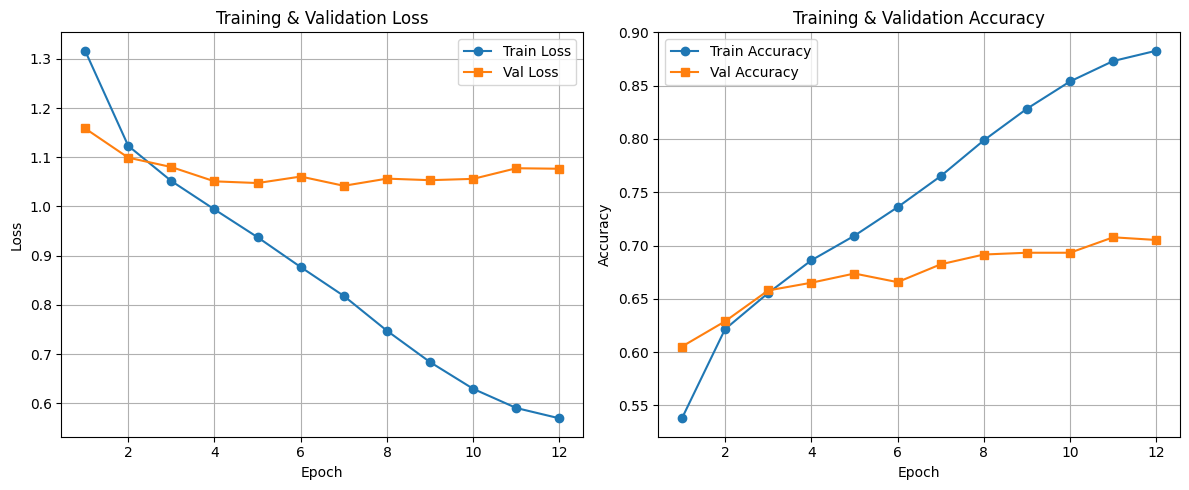

In [6]:
# Cell 6
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, EPOCHS + 1), train_losses, label="Train Loss", marker="o")
plt.plot(range(1, EPOCHS + 1), val_losses, label="Val Loss", marker="s")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(
    range(1, EPOCHS + 1), train_accs, label="Train Accuracy", marker="o"
)
plt.plot(range(1, EPOCHS + 1), val_accs, label="Val Accuracy", marker="s")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training & Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [7]:
# Cell 7
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
  for images, labels in test_loader:
    images = images.to(device)
    outputs = model(images)
    _, predicted = outputs.max(1)
    all_preds.extend(predicted.cpu().numpy())
    all_targets.extend(labels.numpy())

test_acc = accuracy_score(all_targets, all_preds)
macro_f1 = f1_score(all_targets, all_preds, average="macro")
final_score = (macro_f1 * 0.5) + (test_acc * 0.5)

print(f"Test accuracy: {test_acc:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Final_score: {final_score:.4f}")

Test accuracy: 0.7077
Macro F1: 0.6979
Final_score: 0.7028


In [27]:
# Cell 8 - 進階挑戰
import os
import openpyxl

EMOTION_LABELS = [
    "Angry",    # 0
    "Disgust",  # 1
    "Fear",     # 2
    "Happy",    # 3
    "Sad",      # 4
    "Surprise", # 5
    "Neutral",  # 6
]

hard_testset_dir = "/content/進階挑戰附檔/hw4_hard_testset"
answer_xlsx_src  = "/content/進階挑戰附檔.xlsx"
output_xlsx_path = "hw4_hard_predictions.xlsx"

img_files = sorted(
    [f for f in os.listdir(hard_testset_dir) if f.endswith(".jpg")]
)
print(f"共找到 {len(img_files)} 張測試圖片")

hard_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

model.eval()
predictions = {}

with torch.no_grad():
    for fname in img_files:
        img_path = os.path.join(hard_testset_dir, fname)
        img = Image.open(img_path).convert("RGB")
        tensor = hard_test_transform(img).unsqueeze(0).to(device)  # (1, 3, 224, 224)
        output = model(tensor)
        pred_idx = output.argmax(dim=1).item()
        predictions[fname] = EMOTION_LABELS[pred_idx]

print("預測完成，統計：")
from collections import Counter
cnt = Counter(predictions.values())
for emotion, count in sorted(cnt.items()):
    print(f"  {emotion}: {count}")

wb = openpyxl.load_workbook(answer_xlsx_src)
ws = wb.active

for row in ws.iter_rows(min_row=2, max_col=2):
    filename_cell, label_cell = row
    fname = filename_cell.value
    if fname and fname in predictions:
        label_cell.value = predictions[fname]

wb.save(output_xlsx_path)
print(f"\n答案已儲存至：{output_xlsx_path}")

print("\n前 10 筆預測結果：")
print(f"{'filename':<12} {'label'}")
print("-" * 22)
for fname in img_files[:10]:
    print(f"{fname:<12} {predictions[fname]}")

共找到 100 張測試圖片
預測完成，統計：
  Angry: 16
  Disgust: 4
  Fear: 21
  Happy: 8
  Neutral: 16
  Sad: 28
  Surprise: 7

答案已儲存至：hw4_hard_predictions.xlsx

前 10 筆預測結果：
filename     label
----------------------
c001.jpg     Angry
c002.jpg     Angry
c003.jpg     Angry
c004.jpg     Surprise
c005.jpg     Happy
c006.jpg     Sad
c007.jpg     Happy
c008.jpg     Sad
c009.jpg     Angry
c010.jpg     Happy


In [36]:
import os
os.chdir('/content/repo')
  
TOKEN = "YOUR_GITHUB_TOKEN"                                      
!git remote set-url origin https://{TOKEN}@github.com/singstar2500/colab  
!git push

Enumerating objects: 4, done.
Counting objects: 100% (4/4), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (3/3), 5.59 KiB | 5.59 MiB/s, done.
Total 3 (delta 0), reused 0 (delta 0), pack-reused 0
To https://github.com/singstar2500/colab
   887d1f1..c2d1c91  main -> main


In [34]:
import os
os.chdir('/content/repo')
  
    # 確認 token 有沒有設定成功                                               
!git remote -v
!git log --oneline -3
!git push 2>&1

origin	https://YOUR_GITHUB_TOKEN@github.com/singstar2500/colab (fetch)
origin	https://YOUR_GITHUB_TOKEN@github.com/singstar2500/colab (push)
c2d1c91 (HEAD -> main) add hw4 hard predictions
887d1f1 (origin/main, origin/HEAD) add hard testset files and xlsx
01c574b Initial commit
remote: Permission to singstar2500/colab.git denied to singstar2500.
fatal: unable to access 'https://github.com/singstar2500/colab/': The requested URL returned error: 403
